In [7]:
from math import pi
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

Predictions:
- Circuit 1 (RY(π/3)): 0 more often, about 75% 0 and 25% 1
- Circuit 2 (RY(2π/3)): 1 more often, about 25% 0 and 75% 1
- Changing the rotation angle changes the bias

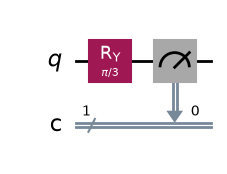

In [8]:
qc1 = QuantumCircuit(1, 1)
qc1.ry(pi/3, 0)
qc1.measure(0, 0)
qc1.draw("mpl")

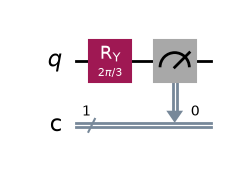

In [9]:
qc2 = QuantumCircuit(1, 1)
qc2.ry(2*pi/3, 0)
qc2.measure(0, 0)
qc2.draw("mpl")

In [10]:
sim = AerSimulator()
c1 = sim.run(qc1, shots=100).result().get_counts()
c2 = sim.run(qc2, shots=100).result().get_counts()
print(c1, c2)

{'0': 76, '1': 24} {'1': 74, '0': 26}


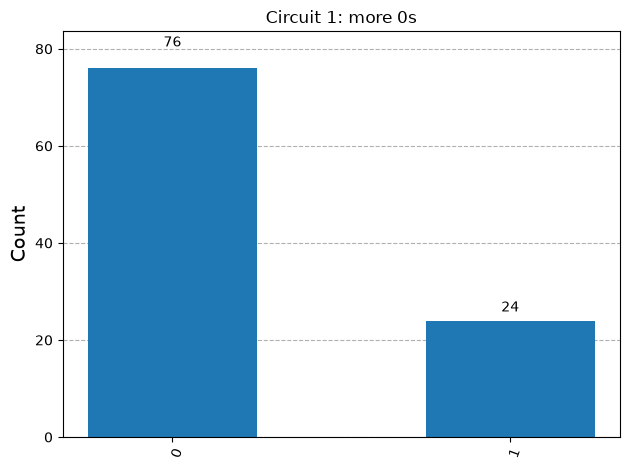

In [11]:
plot_histogram(c1, title="Circuit 1: more 0s")

In [12]:
for name, angle in [("pi/6", pi/6), ("pi/3", pi/3), ("2pi/3", 2*pi/3), ("5pi/6", 5*pi/6)]:
    qc = QuantumCircuit(1, 1)
    qc.ry(angle, 0)
    qc.measure(0, 0)
    print(name, sim.run(qc, shots=100).result().get_counts())

pi/6 {'0': 89, '1': 11}
pi/3 {'0': 75, '1': 25}
2pi/3 {'1': 80, '0': 20}
5pi/6 {'1': 95, '0': 5}


## Comparison: Prediction vs Actual
- **Circuit 1 (RY(π/3)):** Predicted about 75% `0` and 25% `1`. Actual: `{'0': 78, '1': 22}`. 0 occurs more often, as predicted.
- **Circuit 2 (RY(2π/3)):** Predicted about 25% `0` and 75% `1`. Actual: `{'0': 23, '1': 77}`. 1 occurs more often, as predicted.

**How the gates changed the distribution:** The RY gate rotates the qubit away from |0⟩ by the angle θ. The probabilities are P(0) = cos²(θ/2) and P(1) = sin²(θ/2). With θ = π/3, P(0) = 75%. With θ = 2π/3, P(1) = 75%. A larger angle gives a higher chance of 1.

**Effect of changing the angle:** In the extra experiment above, π/6 gave about 89/11 and 5π/6 gave about 5/95, so the bias grows as the angle moves further from π/2, where the result is a fair 50/50 coin.

**How can quantum gates change the probability of obtaining 0 or 1?**

A gate rotates the qubit's state. The probability of measuring 0 or 1 is the squared amplitude of each state. A Hadamard gate gives equal amplitudes (50/50), but a rotation like RY(θ) gives P(1) = sin²(θ/2) and P(0) = cos²(θ/2). A small angle keeps the qubit near |0⟩, so 0 is more likely. An angle near π moves it toward |1⟩, so 1 is more likely. Choosing the gates and angles lets us control the bias.